## TCC – Queimadas X internações respiratórias em Mato Grosso

### 1. Instalação de pacotes

In [1]:
#descomentar e rodar na primeira execução para baixar os pacotes necessários.
#%pip install -r requirements.txt

### 2. Configuração do ambiente

In [2]:
import os, sys, io, zipfile, unicodedata
import numpy as np
import pandas as pd
import requests
from pysus.api.ftp.client import FTP

ANOS = [2022, 2023, 2024, 2025]     
PASTA_INPE = "dados_inpe"
PASTA_SIH  = "dados_sih"

In [3]:
#Variáveis de Ambiente
#Java
os.environ["JAVA_HOME"] = r"C:\java\jdk-11.0.16"
os.environ["PATH"] = os.environ["JAVA_HOME"] + r"\bin;" + os.environ["PATH"]
#Spark
os.environ["SPARK_HOME"] = r"C:\spark\spark-3.5.4-bin-hadoop3"
os.environ["PATH"] = os.environ["SPARK_HOME"] + r"\bin;" + os.environ["PATH"]
#Hadoop
os.environ["HADOOP_HOME"] = r"C:\hadoop"
os.environ["PATH"] = os.environ["HADOOP_HOME"] + r"\bin;" + os.environ["PATH"]
#Pyspark
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

### 3. Inicialização do spark

In [4]:
from pyspark.sql import SparkSession

print("Iniciando Spark...", flush=True)
spark = (
    SparkSession.builder
    .appName("TCC_PUC_2026")
    .master("local[*]")
    .config("spark.sql.shuffle.partitions", "1")
    .config("spark.eventLog.enabled", "false")
    .config("spark.sql.execution.arrow.pyspark.enabled", "true")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("WARN")
print("Sessão criada. Versão do Spark:", spark.version, flush=True)

Iniciando Spark...
Sessão criada. Versão do Spark: 3.5.4


### 4. Dados de queimadas (INPE), um arquivo por ano

In [5]:
URL_INPE = "https://dataserver-coids.inpe.br/queimadas/queimadas/focos/csv/anual/Brasil_sat_ref/focos_br_ref_{ano}.zip"

os.makedirs(PASTA_INPE, exist_ok=True)

for ano in ANOS:
    csv_name = os.path.join(PASTA_INPE, f"focos_br_ref_{ano}.csv")
    #verifica se o arquivo existe para nao precisar baixar novamente
    if not os.path.exists(csv_name):
        print(f"Baixando {ano}...")
        #baixa o arquivo.
        r = requests.get(URL_INPE.format(ano=ano), timeout=600)
        r.raise_for_status()
        #abre o zip direto da memoria, sem salvar o .zip no disco
        with zipfile.ZipFile(io.BytesIO(r.content)) as z:
            #procura o csv dentro do zip
            nome = next(n for n in z.namelist() if n.endswith(".csv"))
            #descompacta e salva o csv direto na PASTA_INPE
            with open(csv_name, "wb") as f:
                f.write(z.read(nome))
    else:
        print(f"arquivo INPE para o ano {ano}, já existe!")


arquivo INPE para o ano 2022, já existe!
arquivo INPE para o ano 2023, já existe!
arquivo INPE para o ano 2024, já existe!
arquivo INPE para o ano 2025, já existe!


### 5. Dados de saúde (DATASUS / SIH), data real de internação

In [6]:
ANO_MIN, ANO_MAX = ANOS[0], ANOS[-1]
ATRASO_MAX_MESES = 4        #internações são processadas em até 4 meses (99,8%) por isso baixamos 4 meses após o último ano

os.makedirs(PASTA_SIH, exist_ok=True)
cols_interesse = ["MUNIC_RES", "DT_INTER", "DIAG_PRINC", "IDADE", "QT_DIARIAS", "MORTE"]

# todos os meses dos anos de análise + os meses de atraso do ano seguinte
periodos = [(a, m) for a in range(ANO_MIN, ANO_MAX + 2) for m in range(1, 13)]
periodos = periodos[:12 * len(ANOS) + ATRASO_MAX_MESES]

#caminho do arquivo csv
def caminho_sih(ano, mes):
    return os.path.join(PASTA_SIH, f"RDMT{str(ano)[-2:]}{mes:02d}.csv")

#verifica se há periodos que precisam ser baixados
faltam = [(a, m) for a, m in periodos if not os.path.exists(caminho_sih(a, m))]
print(f"{len(periodos)} meses necessários, faltam baixar {len(faltam)} arquivos")

if faltam:
    #instancia e conecta no FTP() do pysus
    ftp = FTP()
    await ftp.connect()
    #lista datasets disponiveis
    datasets = await ftp.datasets()
    sih_ds = next(d for d in datasets if d.name == "SIH")
    content = await sih_ds.content

    for ano, mes in faltam:
        dbc_name = f"RDMT{str(ano)[-2:]}{mes:02d}.dbc"
        arq = next((f for f in content if f.name.upper() == dbc_name), None)
        if arq is None:
            print(f"AVISO: {dbc_name} não encontrado no servidor (período ainda não publicado?).")
            continue
        print(f"Baixando {arq.name}...", flush=True)
        #baixa o arquivo com extensão .dbc
        local = await arq.download()
        #transforma em dataframe
        df = await local.load()
        df = df[df["DIAG_PRINC"].str.startswith("J", na=False)]
        #seleciona as colunas desejaveis
        df = df[cols_interesse].assign(MES_REF=mes, ANO_REF=ano)
        #salva com csv
        df.to_csv(caminho_sih(ano, mes), index=False)
        print(f"   -> {len(df):,} internações respiratórias salvas.")

    await ftp.close()


52 meses necessários, faltam baixar 0 arquivos


### 6. Municípios e população (IBGE)

A população é a do **Censo 2022**, usada para todos os anos

In [7]:
#função para remover ascentos.
def remover_acentos(texto):
    if not texto: return ""
    return unicodedata.normalize("NFKD", str(texto)).encode("ASCII", "ignore").decode("ASCII").upper().strip()

#obtém os municipios e codigos do ibge
resp = requests.get("https://servicodados.ibge.gov.br/api/v1/localidades/estados/51/municipios", timeout=60).json()
#cria o dataframe e popula os dados
df_ibge = pd.DataFrame([{
    "cod_ibge_6": str(m["id"])[:6],
    "municipio_oficial": m["nome"],
    "municipio_norm": remover_acentos(m["nome"]),
} for m in resp])

#obtém a populacao conforme o ultimo censo divulgado de 2022
url_pop = "https://servicodados.ibge.gov.br/api/v3/agregados/9514/periodos/2022/variaveis/93?localidades=N6[N3[51]]"
resp_pop = requests.get(url_pop, timeout=60).json()
#cria o dataframe e popula os dados
df_pop = pd.DataFrame([{
    "cod_ibge_6": str(it["localidade"]["id"])[:6],
    "populacao": int(it["serie"]["2022"]),
} for it in resp_pop[0]["resultados"][0]["series"]])
assert df_pop["cod_ibge_6"].is_unique, "Há municípios duplicados na população (verifique a classificação da tabela 9514)."

df_ibge = df_ibge.merge(df_pop, on="cod_ibge_6", how="left")

print("Municípios na lista do IBGE:", len(df_ibge))
print("Municípios com população:", df_ibge["populacao"].notna().sum())
print("População total:", f"{int(df_ibge['populacao'].sum()):,}")
print("Sem população:", df_ibge.loc[df_ibge["populacao"].isna(), "municipio_oficial"].tolist())

Municípios na lista do IBGE: 142
Municípios com população: 141
População total: 3,658,649
Sem população: ['Boa Esperança do Norte']


### 7. Focos de queimada por município e mês (INPE + IBGE)

In [8]:
#lê os focos de cada ano e fica só com MT
partes = []
for ano in ANOS:
    df = pd.read_csv(os.path.join(PASTA_INPE, f"focos_br_ref_{ano}.csv"), usecols=["data_pas", "estado", "municipio"])
    df = df[df["estado"].str.upper() == "MATO GROSSO"]
    df["ano"] = ano                                   # o ano do arquivo é o ano oficial do foco
    df["mes"] = pd.to_datetime(df["data_pas"]).dt.month
    partes.append(df)
foc = pd.concat(partes, ignore_index=True)
print("Focos de MT por ano:", foc.groupby("ano").size().to_dict())

#Tratamento do nome de município que na base do INPE está diferente do IBGE.
foc["municipio_norm"] = foc["municipio"].apply(remover_acentos).replace(
    {"SANTO ANTONIO DO LEVERGER": "SANTO ANTONIO DE LEVERGER"})

#liga cada foco ao código IBGE do município
focos_cod = foc.merge(df_ibge[["cod_ibge_6", "municipio_norm"]], on="municipio_norm", how="left")
print("Focos sem município no IBGE:", focos_cod["cod_ibge_6"].isna().sum(), "(esperado: 0)")

#conta os focos por município, ano e mês
focos_mm = focos_cod.groupby(["cod_ibge_6", "ano", "mes"]).size().rename("qtd_focos").reset_index()
print("Focos por ano:", focos_mm.groupby("ano")["qtd_focos"].sum().to_dict())


Focos de MT por ano: {2022: 29039, 2023: 21723, 2024: 50551, 2025: 11061}
Focos sem município no IBGE: 0 (esperado: 0)
Focos por ano: {2022: 29039, 2023: 21723, 2024: 50551, 2025: 11061}


### 8. Internações pela data real de internação (`DT_INTER`)

In [9]:
#junta os arquivos mensais do SIH
sih = pd.concat([pd.read_csv(caminho_sih(a, m), dtype={"MUNIC_RES": str}) for a, m in periodos],
                ignore_index=True)

#fica só com residentes de MT (código IBGE começa com 51)
sih = sih[sih["MUNIC_RES"].str.startswith("51")].rename(columns={"MUNIC_RES": "cod_ibge_6"})

#ano e mês pela data real da internação (não pelo mês do arquivo)
dt = pd.to_datetime(sih["DT_INTER"])
sih["ano"], sih["mes"] = dt.dt.year, dt.dt.month
sih = sih[sih["ano"].isin(ANOS)]

#atraso entre a internação e o mês em que ela foi processada (justifica o ATRASO_MAX_MESES)
atraso = (sih["ANO_REF"] - sih["ano"]) * 12 + (sih["MES_REF"] - sih["mes"])
print("Atraso de processamento em meses (4 = 4 ou mais):")
print(atraso.clip(upper=4).value_counts().sort_index().to_string())

#conta as internações por município, ano e mês
intern_mm = sih.groupby(["cod_ibge_6", "ano", "mes"]).size().rename("qtd_internacoes").reset_index()
print("\nInternações de MT por ano (data real):", intern_mm.groupby("ano")["qtd_internacoes"].sum().to_dict())


Atraso de processamento em meses (4 = 4 ou mais):
0    51087
1    22841
2     8182
3     9453
4     1377

Internações de MT por ano (data real): {2022: 19449, 2023: 22306, 2024: 24111, 2025: 27074}


### 9. Painel mensal por município: focos, internações e taxas

Cada linha é um município em um mês. Meses sem foco ou internação entram com 0. As taxas são por 100 mil habitantes (Censo 2022), e os lags trazem os focos de 1 e 2 meses antes.


In [10]:
#grade com todos os municípios x todos os meses (mês sem foco ou internação vira 0)
tempo = pd.DataFrame([(a, m) for a in ANOS for m in range(1, 13)], columns=["ano", "mes"])
painel = (df_ibge[["cod_ibge_6", "municipio_oficial", "populacao"]].merge(tempo, how="cross")
          .merge(focos_mm, on=["cod_ibge_6", "ano", "mes"], how="left")
          .merge(intern_mm, on=["cod_ibge_6", "ano", "mes"], how="left"))
painel[["qtd_focos", "qtd_internacoes"]] = painel[["qtd_focos", "qtd_internacoes"]].fillna(0).astype(int)
painel["periodo"] = (painel["ano"] - ANO_MIN) * 12 + painel["mes"]          # 1 .. 12*n_anos

#taxas por 100 mil habitantes
painel["taxa_focos_100k"] = painel["qtd_focos"] / painel["populacao"] * 100000
painel["taxa_internacao_100k"] = painel["qtd_internacoes"] / painel["populacao"] * 100000

#focos de 1 e 2 meses antes (atravessam a virada de ano)
painel = painel.sort_values(["cod_ibge_6", "periodo"]).reset_index(drop=True)
for k in (1, 2):
    painel[f"taxa_focos_lag{k}"] = painel.groupby("cod_ibge_6")["taxa_focos_100k"].shift(k)

print("Linhas do painel:", len(painel), "| focos:", f"{painel['qtd_focos'].sum():,}",
      "| internações:", f"{painel['qtd_internacoes'].sum():,}")

#totais do estado por mês
resumo_mensal = painel.groupby(["ano", "mes", "periodo"])[["qtd_focos", "qtd_internacoes"]].sum().reset_index()
print("\nFocos por mês:")
print(resumo_mensal.pivot(index="ano", columns="mes", values="qtd_focos").to_string())
print("\nInternações por mês:")
print(resumo_mensal.pivot(index="ano", columns="mes", values="qtd_internacoes").to_string())

painel.to_csv("base_painel_multiano.csv", index=False)
resumo_mensal.to_csv("resumo_mensal_multiano.csv", index=False)


Linhas do painel: 6816 | focos: 112,374 | internações: 92,940

Focos por mês:
mes    1    2     3    4     5     6     7      8      9     10    11    12
ano                                                                        
2022  556  472   543  526  2533  2210  1919   7699   8876  1548  1746   411
2023  240  515   576  644  1666  2447  1453   2626   4219  2454  3705  1178
2024  847  863  1624  797  1996  2671  2472  14617  19964  3814   435   451
2025  256  239   429  222   816  1576  1017   2322   2294  1410   275   205

Internações por mês:
mes     1     2     3     4     5     6     7     8     9     10    11    12
ano                                                                         
2022  1827   987  1758  2019  1927  1903  1588  1472  1450  1734  1507  1277
2023  1160  1606  2519  2733  2611  2022  1851  1841  1592  1578  1387  1406
2024  1275  1378  2124  3015  3014  2356  1975  1879  1997  1854  1678  1566
2025  1544  1746  2392  2831  3413  2874  2376  2126  2063 

### 10. Correlação entre focos e internações

Pearson entre a taxa de focos (no mês, 1 e 2 meses antes) e a taxa de internação, de três formas: sem controle, controlando o município e a sazonalidade, e controlando o município e o mês-calendário. O intervalo de confiança de 95% vem de um bootstrap de municípios.


In [11]:
BOOTSTRAP_REPS = 500    #reamostragens do intervalo de confiança das correlações
ALVO = "taxa_internacao_100k"
FOCOS = {"T": "taxa_focos_100k", "T-1": "taxa_focos_lag1", "T-2": "taxa_focos_lag2"}
cols_corr = list(FOCOS.values()) + [ALVO]
#tira os 2 primeiros meses (sem lag) e o município sem população
d = painel.dropna(subset=cols_corr)

def correlacoes(df, controle):
    """Pearson entre focos e internações. Com controle, tira antes a média do município e a do período (efeitos fixos)."""
    x = df[cols_corr]
    if controle:
        x = (x - df.groupby("cod_ibge_6")[cols_corr].transform("mean")
               - df.groupby(controle)[cols_corr].transform("mean") + x.mean())
    return {n: x[c].corr(x[ALVO]) for n, c in FOCOS.items()}

CONTROLES = {
    "bruta (sem controles)": None,
    "município + mês do ano (sazonalidade)": "mes",
    "município + mês-calendário (ano-mês)": "periodo",
}

#bootstrap: sorteia municípios com reposição para montar o intervalo de confiança
rs = np.random.RandomState(42)
municipios = d["cod_ibge_6"].unique()
grupos = {m: d[d["cod_ibge_6"] == m] for m in municipios}
linhas = []
for nome, controle in CONTROLES.items():
    boot = []
    for _ in range(BOOTSTRAP_REPS):
        amostra = rs.choice(municipios, len(municipios), replace=True)
        #município sorteado 2x entra como 2 municípios diferentes
        b = pd.concat([grupos[m].assign(cod_ibge_6=i) for i, m in enumerate(amostra)])
        boot.append(correlacoes(b, controle))
    boot = pd.DataFrame(boot)
    for n, r in correlacoes(d, controle).items():
        lo, hi = np.percentile(boot[n], [2.5, 97.5])
        linhas.append({"especificação": nome, "focos em": n, "Pearson": r, "IC95_inf": lo, "IC95_sup": hi})

corr_fe_tab = pd.DataFrame(linhas)
print(f"Correlação focos × internações (IC 95% por bootstrap de municípios, {BOOTSTRAP_REPS} reamostragens):")
print(corr_fe_tab.round(4).to_string(index=False))
corr_fe_tab.to_csv("corr_efeitos_fixos_multiano.csv", index=False)


Correlação focos × internações (IC 95% por bootstrap de municípios, 500 reamostragens):
                        especificação focos em  Pearson  IC95_inf  IC95_sup
                bruta (sem controles)        T   0.0198   -0.0442    0.0735
                bruta (sem controles)      T-1   0.0039   -0.0473    0.0448
                bruta (sem controles)      T-2  -0.0230   -0.0703    0.0144
município + mês do ano (sazonalidade)        T   0.0091   -0.0363    0.0556
município + mês do ano (sazonalidade)      T-1   0.0017   -0.0331    0.0282
município + mês do ano (sazonalidade)      T-2  -0.0201   -0.0450    0.0028
 município + mês-calendário (ano-mês)        T   0.0199   -0.0216    0.0653
 município + mês-calendário (ano-mês)      T-1   0.0053   -0.0258    0.0317
 município + mês-calendário (ano-mês)      T-2  -0.0161   -0.0406    0.0085


### 11. Agrupamento dos municípios (K-Means)

Os municípios são agrupados em 3 clusters pelo perfil médio do período: taxa de focos e população (padronizadas). A taxa de internação não entra no agrupamento, porque é a variável que os modelos tentam prever. Ela aparece só na descrição dos clusters. O cluster entra depois como variável nos modelos.


In [12]:
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.clustering import KMeans

#perfil médio de cada município no período todo
perfil = (painel.dropna(subset=["populacao"])
          .groupby(["cod_ibge_6", "municipio_oficial"])
          .agg(taxa_focos_media=("taxa_focos_100k", "mean"),
               taxa_internacao_media=("taxa_internacao_100k", "mean"),
               populacao=("populacao", "first"))
          .reset_index())

#agrupa pela taxa de focos e população (padronizadas). A taxa de internação fica de fora porque é o que os modelos vão prever
colunas = ["taxa_focos_media", "populacao"]
sdf = spark.createDataFrame(perfil[["cod_ibge_6"] + colunas])
sdf = VectorAssembler(inputCols=colunas, outputCol="features_raw").transform(sdf)
sdf = StandardScaler(inputCol="features_raw", outputCol="features", withMean=True).fit(sdf).transform(sdf)
modelo = KMeans(k=3, seed=42, predictionCol="cluster").fit(sdf)
clusters = modelo.transform(sdf).select("cod_ibge_6", "cluster").toPandas()
perfil = perfil.merge(clusters, on="cod_ibge_6")

#leva o cluster para o painel (o drop evita coluna duplicada se a célula rodar de novo)
painel = (painel.drop(columns="cluster", errors="ignore")
                .merge(clusters, on="cod_ibge_6", how="left"))

#descrição dos clusters (a taxa de internação aparece só aqui, depois do agrupamento)
resumo_clusters = perfil.groupby("cluster").agg(
    municipios=("cod_ibge_6", "count"),
    pop_media=("populacao", "mean"),
    pop_mediana=("populacao", "median"),
    taxa_focos_media=("taxa_focos_media", "mean"),
    taxa_internacao_media=("taxa_internacao_media", "mean"),
).round(2)
print(resumo_clusters.to_string())

#exemplos: os 6 maiores municípios de cada cluster
exemplos = (perfil.sort_values("populacao", ascending=False)
            .groupby("cluster")["municipio_oficial"].apply(lambda s: ", ".join(s.head(6))))
print("\n" + exemplos.to_string())

resumo_clusters.to_csv("perfil_clusters_multiano.csv")
perfil.to_csv("perfil_municipios_multiano.csv", index=False)

         municipios  pop_media  pop_mediana  taxa_focos_media  taxa_internacao_media
cluster                                                                             
0               125   23216.77      10966.0             93.46                  66.06
1                 1  650877.00     650877.0              2.69                  28.08
2                15    7045.07       5846.0            726.28                  73.93

cluster
0    Várzea Grande, Rondonópolis, Sinop, Sorriso, T...
1                                               Cuiabá
2    Colniza, Marcelândia, Feliz Natal, Apiacás, Sa...


### 12. Modelos de previsão da taxa de internação

Random Forest e GBT (Spark) prevendo a taxa mensal de internação respiratória de cada município. A pergunta é se as variáveis de focos melhoram a previsão.

* **Variáveis:** todos os conjuntos usam cluster, mês e população.
  * **A:** focos no mês (T), 1 mês antes (T-1) e 2 meses antes (T-2).
  * **B:** só T-1 e T-2, ou seja, prever sem conhecer os focos do mês atual.
  * **C:** sem focos, usado como comparação.
* **Divisões treino/teste:**
  1. **Aleatória 80/20:** sorteia as linhas.
  2. **Por município:** 20% dos municípios ficam só no teste. Mede se o modelo serve para municípios que ele nunca viu.
  3. **Por tempo:** treina nos anos anteriores e testa no último ano inteiro. É a situação mais próxima de uso real.
* **Linhas de base (previsões sem modelo):** média global, média do município e média do município + efeito do mês (sazonalidade).
* **Como ler:** os focos só agregam informação se o R² de A ou B for maior que o de C e que o da base "município + mês".


In [13]:
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import RandomForestRegressor, GBTRegressor

#base de modelagem: tira os 2 primeiros meses (sem lag) e o município sem população
ml = painel.dropna(subset=["populacao", "taxa_focos_lag2"]).copy()
#cluster vira variáveis 0/1 (cl_0, cl_1, cl_2)
ml = ml.join(pd.get_dummies(ml["cluster"].astype(int), prefix="cl", dtype=float))
cl_cols = [c for c in ml.columns if c.startswith("cl_")]

CONJUNTOS = {
    "A: focos T,T-1,T-2": cl_cols + ["mes", "taxa_focos_100k", "taxa_focos_lag1", "taxa_focos_lag2", "populacao"],
    "B: focos T-1,T-2":   cl_cols + ["mes", "taxa_focos_lag1", "taxa_focos_lag2", "populacao"],
    "C: sem focos":       cl_cols + ["mes", "populacao"],
}

def split_aleatorio(df):
    #80% das linhas no treino e 20% no teste
    idx = np.random.RandomState(42).permutation(len(df))
    n = int(0.8 * len(df))
    return df.iloc[idx[:n]], df.iloc[idx[n:]]

def split_municipio(df):
    #20% dos municípios ficam só no teste
    muns = np.array(sorted(df["cod_ibge_6"].unique()))
    teste = np.random.RandomState(42).choice(muns, round(0.2 * len(muns)), replace=False)
    em_teste = df["cod_ibge_6"].isin(teste)
    return df[~em_teste], df[em_teste]

def split_tempo(df):
    #treina nos anos anteriores e testa no último ano
    return df[df["ano"] < ANO_MAX], df[df["ano"] == ANO_MAX]

SPLIT_TEMPO = f"3 por tempo (treino {ANO_MIN}-{ANO_MAX - 1}, teste {ANO_MAX})"
SPLITS = {"1 aleatória 80/20": split_aleatorio, "2 por município": split_municipio, SPLIT_TEMPO: split_tempo}

def metricas(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    return {"rmse": np.sqrt(np.mean((y - p) ** 2)),
            "mae": np.mean(np.abs(y - p)),
            "r2": 1 - np.sum((y - p) ** 2) / np.sum((y - y.mean()) ** 2)}

def linhas_de_base(tr, te):
    """Previsões sem modelo, que os focos precisam superar."""
    g = tr[ALVO].mean()
    media_mun = te["cod_ibge_6"].map(tr.groupby("cod_ibge_6")[ALVO].mean()).fillna(g)
    efeito_mes = te["mes"].map(tr.groupby("mes")[ALVO].mean() - g).fillna(0)
    return {"Base: média global": np.full(len(te), g),
            "Base: média do município": media_mun,
            "Base: município + mês (sazonal)": media_mun + efeito_mes}

def para_spark(df, cols):
    sdf = spark.createDataFrame(df[cols + [ALVO]].astype(float))
    return VectorAssembler(inputCols=cols, outputCol="features").transform(sdf)

ESTIMADORES = {
    "Random Forest": RandomForestRegressor(labelCol=ALVO, numTrees=100, maxDepth=6, seed=42),
    "GBT":           GBTRegressor(labelCol=ALVO, maxIter=50, maxDepth=5, seed=42),
}

linhas, PREDS, MODELOS = [], {}, {}
for nome_split, dividir in SPLITS.items():
    tr, te = dividir(ml)
    tamanhos = {"n_treino": len(tr), "n_teste": len(te)}
    for nome_b, p in linhas_de_base(tr, te).items():
        linhas.append({"divisão": nome_split, "variáveis": "-", "modelo": nome_b, **tamanhos, **metricas(te[ALVO], p)})
    for nome_c, cols in CONJUNTOS.items():
        tr_s, te_s = para_spark(tr, cols), para_spark(te, cols)
        for nome_m, est in ESTIMADORES.items():
            modelo = est.fit(tr_s)
            pred = modelo.transform(te_s).select(ALVO, "prediction").toPandas()
            linhas.append({"divisão": nome_split, "variáveis": nome_c, "modelo": nome_m, **tamanhos,
                           **metricas(pred[ALVO], pred["prediction"])})
            PREDS[(nome_split, nome_c, nome_m)] = pred
            MODELOS[(nome_split, nome_c, nome_m)] = (cols, modelo)
    print("Concluído:", nome_split, flush=True)

resultados = pd.DataFrame(linhas)
resultados.to_csv("resultados_modelos_multiano.csv", index=False)

pd.set_option("display.width", 250)
for metrica, titulo in [("r2", "R² no teste (maior é melhor; 0 = igual a prever a média)"),
                        ("mae", "MAE no teste (menor é melhor)"),
                        ("rmse", "RMSE no teste (menor é melhor)")]:
    print(f"\n===== {titulo} =====")
    print(resultados.pivot_table(index=["variáveis", "modelo"], columns="divisão", values=metrica).round(3).to_string())

Concluído: 1 aleatória 80/20
Concluído: 2 por município
Concluído: 3 por tempo (treino 2022-2024, teste 2025)

===== R² no teste (maior é melhor; 0 = igual a prever a média) =====
divisão                                             1 aleatória 80/20  2 por município  3 por tempo (treino 2022-2024, teste 2025)
variáveis          modelo                                                                                                         
-                  Base: município + mês (sazonal)              0.497            0.045                                       0.365
                   Base: média do município                     0.437           -0.013                                       0.310
                   Base: média global                          -0.000           -0.013                                      -0.039
A: focos T,T-1,T-2 GBT                                          0.213           -0.149                                       0.085
                   Random Forest  

### 13. Série mensal de focos e internações

Totais mensais de Mato Grosso em dois painéis com o mesmo eixo de tempo. Permite comparar a sazonalidade: os focos se concentram em agosto e setembro, enquanto as internações têm pico em abril e maio.


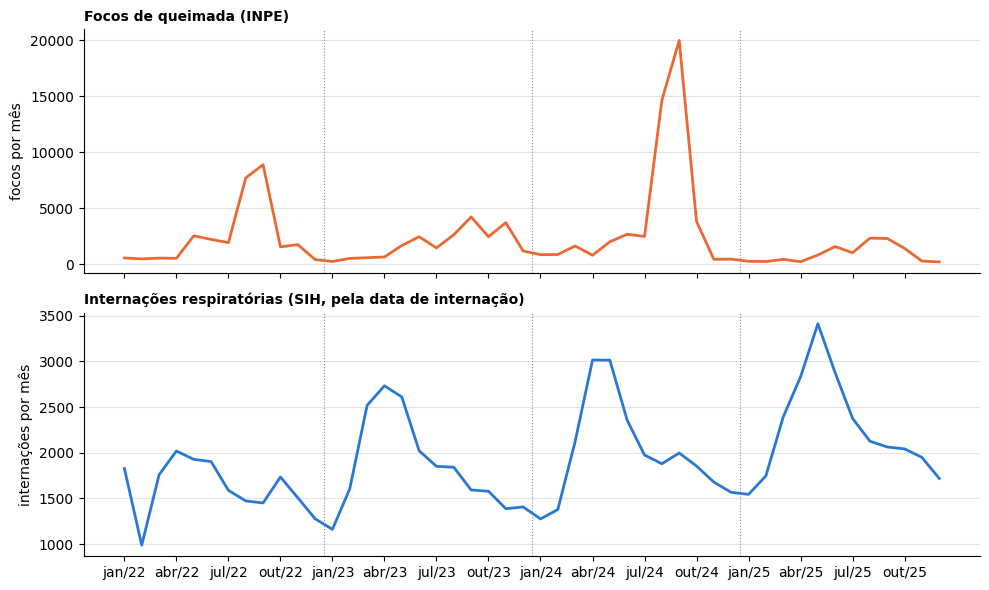

In [14]:
import matplotlib.pyplot as plt

AZUL, LARANJA = "#2a78d6", "#eb6834"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

#série mensal em dois painéis com o mesmo eixo de tempo (sem eixo duplo)
fig, (p1, p2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
p1.plot(resumo_mensal["periodo"], resumo_mensal["qtd_focos"], color=LARANJA, lw=2)
p2.plot(resumo_mensal["periodo"], resumo_mensal["qtd_internacoes"], color=AZUL, lw=2)
p1.set_title("Focos de queimada (INPE)", loc="left", fontweight="bold", fontsize=10)
p2.set_title("Internações respiratórias (SIH, pela data de internação)", loc="left", fontweight="bold", fontsize=10)
p1.set_ylabel("focos por mês")
p2.set_ylabel("internações por mês")

for ax in (p1, p2):
    ax.grid(axis="y", color="#e4e3df")
    ax.set_axisbelow(True)
    #linha pontilhada na virada de cada ano
    for a in ANOS[1:]:
        ax.axvline((a - ANO_MIN) * 12 + 0.5, color="#8a8984", lw=0.8, ls=":")

#marca jan, abr, jul e out de cada ano
meses = {1: "jan", 4: "abr", 7: "jul", 10: "out"}
p2.set_xticks([(a - ANO_MIN) * 12 + m for a in ANOS for m in meses])
p2.set_xticklabels([f"{nome}/{str(a)[-2:]}" for a in ANOS for nome in meses.values()])

fig.tight_layout()
fig.savefig("grafico1_serie_mensal_multiano.png", dpi=200)
plt.show()

### 14. Melhor modelo com focos (teste no último ano)

Entre os modelos que usam focos (conjuntos A e B), o de maior R² na divisão por tempo. À esquerda, o peso de cada variável na previsão; à direita, a taxa real x a prevista em cada município e mês do ano de teste. Quanto mais perto da linha tracejada, melhor a previsão.


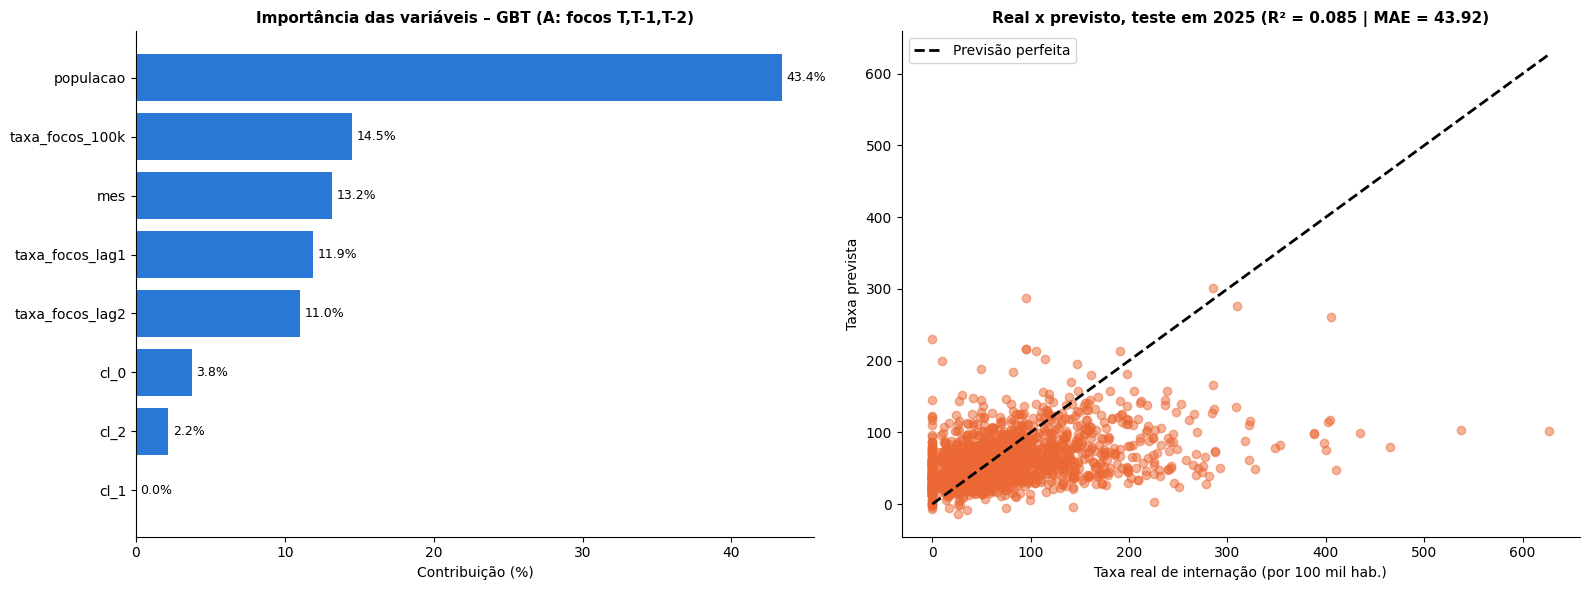

In [15]:
#melhor modelo com focos (A ou B) na divisão por tempo
cand = resultados[(resultados["divisão"] == SPLIT_TEMPO) & resultados["variáveis"].str.startswith(("A:", "B:"))]
melhor = cand.sort_values("r2", ascending=False).iloc[0]
chave = (melhor["divisão"], melhor["variáveis"], melhor["modelo"])
cols_m, modelo_m = MODELOS[chave]
pred_m = PREDS[chave]
imp = pd.Series(modelo_m.featureImportances.toArray() * 100, index=cols_m).sort_values()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 6))

#importância das variáveis
a1.barh(imp.index, imp.values, color=AZUL)
for i, v in enumerate(imp.values):
    a1.text(v + 0.3, i, f"{v:.1f}%", va="center", fontsize=9)
a1.set_title(f"Importância das variáveis – {melhor['modelo']} ({melhor['variáveis']})", fontweight="bold", fontsize=11)
a1.set_xlabel("Contribuição (%)")

#real x previsto no ano de teste
a2.scatter(pred_m[ALVO], pred_m["prediction"], alpha=0.5, color=LARANJA)
lim = max(pred_m[ALVO].max(), pred_m["prediction"].max())
a2.plot([0, lim], [0, lim], "k--", lw=2, label="Previsão perfeita")
a2.set_title(f"Real x previsto, teste em {ANO_MAX} (R² = {melhor['r2']:.3f} | MAE = {melhor['mae']:.2f})",
             fontweight="bold", fontsize=11)
a2.set_xlabel("Taxa real de internação (por 100 mil hab.)")
a2.set_ylabel("Taxa prevista")
a2.legend()

fig.tight_layout()
fig.savefig("grafico2_modelo_multiano.png", dpi=200)
plt.show()


### 15. Resumo dos resultados

Compara o melhor R² no teste em cada divisão: modelos com focos (A ou B), sem focos (C) e as linhas de base. Se "com focos" não supera "sem focos" nem a "base município + mês", os focos de queimada não acrescentam informação além do perfil do município e da sazonalidade.


In [16]:
#tamanho da base
print("Anos:", ANOS)
print("Municípios no painel:", painel["cod_ibge_6"].nunique(), "| municípios modelados:", ml["cod_ibge_6"].nunique())
print("Focos em MT:", f"{painel['qtd_focos'].sum():,}", "| internações:", f"{painel['qtd_internacoes'].sum():,}")
print("Municípios por cluster:", perfil["cluster"].value_counts().sort_index().to_dict())

#os focos agregam algo? melhor R² de cada grupo em cada divisão
def melhor_r2(filtro):
    return resultados[filtro].groupby("divisão")["r2"].max()

var, mod = resultados["variáveis"], resultados["modelo"]
comparacao = pd.DataFrame({
    "com focos (A/B)":      melhor_r2(var.str.startswith(("A:", "B:"))),
    "sem focos (C)":        melhor_r2(var.str.startswith("C:")),
    "base município":       melhor_r2(mod == "Base: média do município"),
    "base município + mês": melhor_r2(mod == "Base: município + mês (sazonal)"),
})
comparacao["diferença (com - sem)"] = comparacao["com focos (A/B)"] - comparacao["sem focos (C)"]
print("\nR² no teste:")
print(comparacao.round(3).to_string())


Anos: [2022, 2023, 2024, 2025]
Municípios no painel: 142 | municípios modelados: 141
Focos em MT: 112,374 | internações: 92,940
Municípios por cluster: {0: 125, 1: 1, 2: 15}

R² no teste:
                                            com focos (A/B)  sem focos (C)  base município  base município + mês  diferença (com - sem)
divisão                                                                                                                                
1 aleatória 80/20                                     0.217          0.203           0.437                 0.497                  0.014
2 por município                                      -0.075         -0.049          -0.013                 0.045                 -0.026
3 por tempo (treino 2022-2024, teste 2025)            0.085          0.129           0.310                 0.365                 -0.044
